# 03 — Recovery before vs after the FTR change

10,000 encounters per cell, ADR 0006's matched-CDaRR condition. *Before*: FTR-family recovery judges the standing resolution command (CDaRR, and blueskycdarr until 2026-11-04). *After*: it judges the nominal return course (blueskycdarr working tree).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import beta

import blueskycdarr.episode as ep
from blueskycdarr import Config, SimulationConfig, UncertaintyConfig, FTR, PastCPA, ProbabilisticFTR
from blueskycdarr.aircraft import MULTIROTOR
from blueskycdarr.geo import track_components
from blueskycdarr.rng import child, root_seed_sequence
from dataclasses import replace

from blueskycdarr.scenario import PairwiseEncounter

# ADR 0006's matched-CDaRR condition: dpsi 90, dcpa 0, tlos 180 s, lookahead 120 s, RPZ 50 m,
# pos 10 m / vel 1 m/s (95%), 20 kt M600, margin 1.05.
CONFIG = Config(uncertainty=UncertaintyConfig(10.0, 1.0),
                simulation=SimulationConfig(dt=0.2, cdr_dt=1.0, t_max=600.0, done_timeout=10.0))
SCENARIO = PairwiseEncounter(speed=10.2889, dpsi=90.0, dcpa=0.0, tlos=180.0)   # 100 pairs per episode
N_EPISODES = 100                                                               # 100 x 100 = 10,000 encounters
RECOVERIES = {"PastCPA": PastCPA(), "FTR": FTR(), "ProbabilisticFTR": ProbabilisticFTR()}
CDARR = {"PastCPA": 0.0004, "FTR": 0.0211, "ProbabilisticFTR": 0.0005}       # CDaRR exp1, 10k pairs (ADR 0006)
RPZ = CONFIG.conflict.rpz


def episode(seq, recovery, before, scenario=SCENARIO, recorder=None):
    """One episode. before=True: recovery judges the standing resolution command (CDaRR / old port);
    before=False: recovery judges the nominal return course (current blueskycdarr working tree)."""
    if before:
        tick, mask, cur = ep._cdr_tick, ep.recovered_mask, {}

        def tick_capture(world, ctx, state, streams, t, truth):
            cur["state"] = state
            return tick(world, ctx, state, streams, t, truth)

        def mask_commanded(rec, **kw):
            s = cur["state"]
            kw["desired_v"] = track_components(s.cmd_trk, s.cmd_gs)
            return mask(rec, **kw)

        ep._cdr_tick, ep.recovered_mask = tick_capture, mask_commanded
    try:
        return ep.run_episode(scenario, MULTIROTOR, CONFIG, seq, recovery, recorder=recorder)
    finally:
        if before:
            ep._cdr_tick, ep.recovered_mask = tick, mask

In [2]:
root = root_seed_sequence(7)
seqs = [child(root, j) for j in range(N_EPISODES)]     # same encounters for every cell (common random numbers)
min_sep, rows = {}, []
for version, before in (("before (CDaRR, judges command)", True), ("after (judges nominal)", False)):
    for name, rec in RECOVERIES.items():
        eps = Parallel(n_jobs=6)(delayed(episode)(s, rec, before) for s in seqs)
        sep = np.concatenate([e.min_sep for e in eps])
        k, n = int((sep < RPZ).sum()), sep.size
        lo = beta.ppf(0.025, k + 0.5, n - k + 0.5) if k > 0 else 0.0      # Jeffreys 95% interval
        hi = beta.ppf(0.975, k + 0.5, n - k + 0.5)
        min_sep[version, name] = sep
        rows.append({"version": version, "recovery": name, "LoS": f"{k}/{n}", "P(LoS)": k / n,
                     "95% CI": f"[{lo:.1e}, {hi:.1e}]", "CDaRR": CDARR[name],
                     "median min sep [m]": np.median(sep), "unsettled episodes": sum(not e.settled for e in eps)})
        print(rows[-1], flush=True)
table = pd.DataFrame(rows).set_index(["recovery", "version"]).sort_index()
table

{'version': 'before (CDaRR, judges command)', 'recovery': 'PastCPA', 'LoS': '0/10000', 'P(LoS)': 0.0, '95% CI': '[0.0e+00, 2.5e-04]', 'CDaRR': 0.0004, 'median min sep [m]': np.float64(102.90259692670446), 'unsettled episodes': 0}


{'version': 'before (CDaRR, judges command)', 'recovery': 'FTR', 'LoS': '417/10000', 'P(LoS)': 0.0417, '95% CI': '[3.8e-02, 4.6e-02]', 'CDaRR': 0.0211, 'median min sep [m]': np.float64(54.42489307103375), 'unsettled episodes': 0}


{'version': 'before (CDaRR, judges command)', 'recovery': 'ProbabilisticFTR', 'LoS': '0/10000', 'P(LoS)': 0.0, '95% CI': '[0.0e+00, 2.5e-04]', 'CDaRR': 0.0005, 'median min sep [m]': np.float64(68.10078587014519), 'unsettled episodes': 0}


{'version': 'after (judges nominal)', 'recovery': 'PastCPA', 'LoS': '0/10000', 'P(LoS)': 0.0, '95% CI': '[0.0e+00, 2.5e-04]', 'CDaRR': 0.0004, 'median min sep [m]': np.float64(102.90259692670446), 'unsettled episodes': 0}


{'version': 'after (judges nominal)', 'recovery': 'FTR', 'LoS': '0/10000', 'P(LoS)': 0.0, '95% CI': '[0.0e+00, 2.5e-04]', 'CDaRR': 0.0211, 'median min sep [m]': np.float64(62.964460912811006), 'unsettled episodes': 0}


{'version': 'after (judges nominal)', 'recovery': 'ProbabilisticFTR', 'LoS': '0/10000', 'P(LoS)': 0.0, '95% CI': '[0.0e+00, 2.5e-04]', 'CDaRR': 0.0005, 'median min sep [m]': np.float64(85.88572324365573), 'unsettled episodes': 0}


LoS  P(LoS)  \
recovery         version                                             
FTR              after (judges nominal)            0/10000  0.0000   
                 before (CDaRR, judges command)  417/10000  0.0417   
PastCPA          after (judges nominal)            0/10000  0.0000   
                 before (CDaRR, judges command)    0/10000  0.0000   
ProbabilisticFTR after (judges nominal)            0/10000  0.0000   
                 before (CDaRR, judges command)    0/10000  0.0000   

                                                             95% CI   CDaRR  \
recovery         version                                                      
FTR              after (judges nominal)          [0.0e+00, 2.5e-04]  0.0211   
                 before (CDaRR, judges command)  [3.8e-02, 4.6e-02]  0.0211   
PastCPA          after (judges nominal)          [0.0e+00, 2.5e-04]  0.0004   
                 before (CDaRR, judges command)  [0.0e+00, 2.5e-04]  0.0004   
ProbabilisticFTR after (judges nominal)          [0.0e+00, 2.5e-04]  0.0005   
                 before (CDaRR, judges command)  [0.0e+00, 2.5e-04]  0.0005   

                                                 median min sep [m]  \
recovery         version                                              
FTR              after (judges nominal)                   62.964461   
                 before (CDaRR, judges command)           54.424893   
PastCPA          after (judges nominal)                  102.902597   
                 before (CDaRR, judges command)          102.902597   
ProbabilisticFTR after (judges nominal)                   85.885723   
                 before (CDaRR, judges command)           68.100786   

                                                 unsettled episodes  
recovery         version                                             
FTR              after (judges nominal)                           0  
                 before (CDaRR, judges command)                   0  
PastCPA          after (judges nominal)                           0  
                 before (CDaRR, judges command)                   0  
ProbabilisticFTR after (judges nominal)                           0  
                 before (CDaRR, judges command)                   0

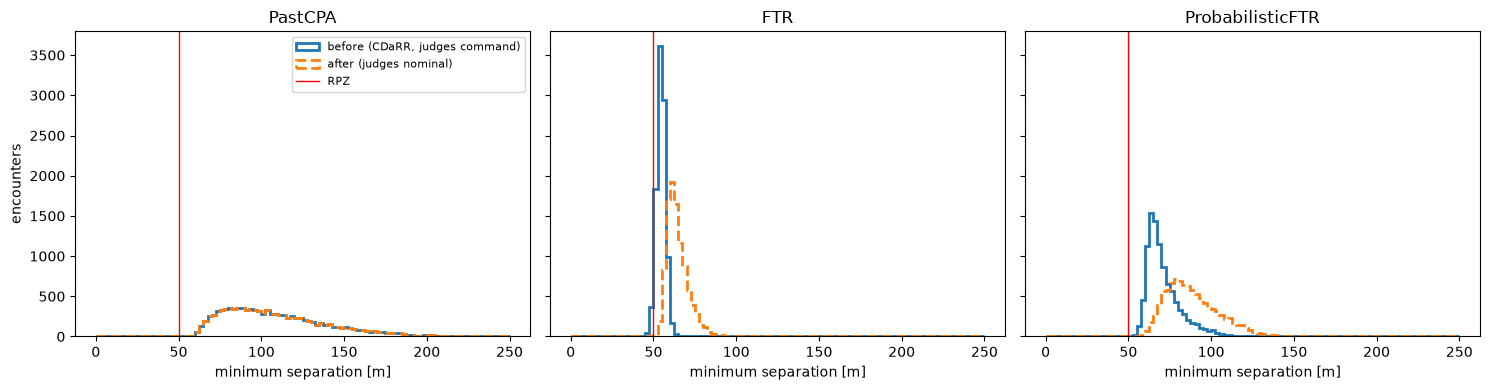

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = np.linspace(0, 250, 101)
for ax, name in zip(axes, RECOVERIES):
    for version, ls in (("before (CDaRR, judges command)", "-"), ("after (judges nominal)", "--")):
        ax.hist(min_sep[version, name], bins=bins, histtype="step", lw=2, ls=ls, label=version)
    ax.axvline(RPZ, color="r", lw=1, label="RPZ")
    ax.set_title(name); ax.set_xlabel("minimum separation [m]")
axes[0].set_ylabel("encounters"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

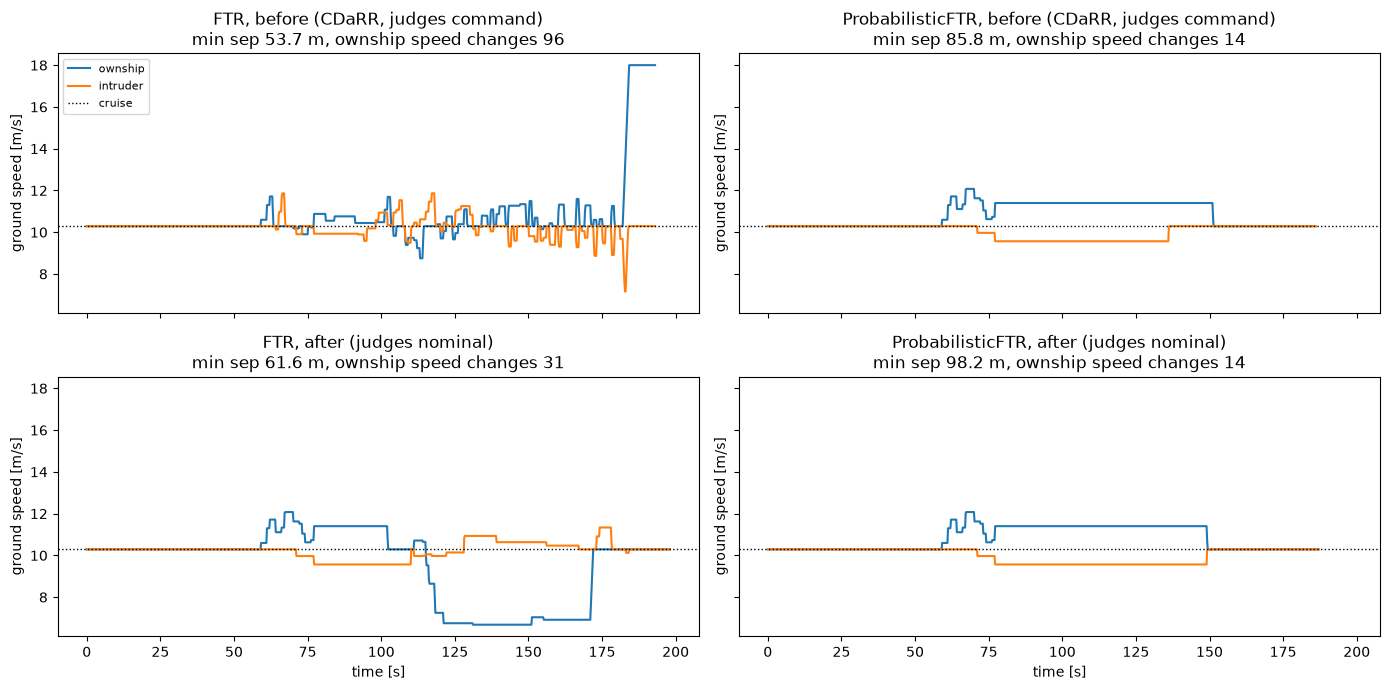

In [4]:
# One example encounter (episode 0, pair 0): ground speed of both aircraft.
one = replace(SCENARIO, pairs=(1, 1))
v_nom = SCENARIO.speed
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
for col, name in enumerate(("FTR", "ProbabilisticFTR")):
    for row, (version, before) in enumerate((("before (CDaRR, judges command)", True), ("after (judges nominal)", False))):
        log = []
        res = episode(seqs[0], RECOVERIES[name], before, scenario=one,
                      recorder=lambda t, truth, d: log.append((t, truth.gs[0], truth.gs[1])))
        t, gs_own, gs_intr = np.array(log).T
        changes = int(np.sum(np.abs(np.diff(gs_own)) > 0.05))
        ax = axes[row, col]
        ax.plot(t, gs_own, lw=1.5, label="ownship")
        ax.plot(t, gs_intr, lw=1.5, label="intruder")
        ax.axhline(v_nom, color="k", lw=1, ls=":", label="cruise")
        ax.set_title(f"{name}, {version}\nmin sep {res.min_sep[0]:.1f} m, ownship speed changes {changes}")
        ax.set_ylabel("ground speed [m/s]")
        if row == 1:
            ax.set_xlabel("time [s]")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()